# CA_1 Statistical Techniques
Benjamin Aaron Rojas Salas "Surviving the Grey: an Empirical Study on Irish Weather and Mood."

# Importing Python Libraries

In [1]:
# We import the libraries we will be using
# 1. Pandas works to manipulate, analyze, clean and transform databases
import pandas as pd
# 2. Numpy is a fundamental open source library for scientific, data science and machine learning for Python
import numpy as np
# 3. Matplotlib is a low level data visualization library in Python    .Pyplot manages figures areas and labels
import matplotlib.pyplot as plt
# 4. Scipy library is used for advanced statistical analysis and probabilistic modelling
from scipy.stats import norm
from scipy import stats
# 5. Seaborn serves as a high level visualization library specialized in designing statistical graphs
import seaborn as sns

# Data Preparation

In [2]:
# Bring the dataset I will be working with.   df = dataframe 

df_original = pd.read_csv('Data_CA1.csv')
# Create a copy of the dataframe
df =df_original.copy()

# Data Cleaning

In [3]:
# Displays the first 5 rows of the dataset
df.head()

,Timestamp,How do you feel when Google’s forecast gets it wrong and the Irish weather catches you by surprise?,"When the Irish weather ""wins"" against Google's predictions, my level of frustration is:",What of the following ranges includes your age?,"How would you rate your general energy level on a standard grey, overcast Irish day?",What is your current primary occupation in Ireland?,"Which of the following situations can't you cope with, making you get mad at the weather while waiting for the bus?",Does waking up to a rainy morning directly affect your productivity during the first hours of your study or work session?,How many beverages (coffee/tea/beer) do you usually drink to lift your spirits when your mood is down due to the weather?,How many times per week do you find yourself waiting for the bus under the rain or wind?,"How much extra money (in Euros €) are you likely to spend on socializing (pints, coffee, eating out) on an unexpectedly sunny day compared to a grey day?",During which Irish season do you feel your academic/work motivation drops the most?,"On a scale from 1 to 10, how drastically does your mood improve the moment the sun comes out on a cloudy day?",How happy or positive do you generally feel under the following weather conditions?,A pint in a cozy Irish pub is the only metric that can make you completely forget how the weather is outside.
0,2026/09/26 11:47:35 am GMT,Prepared ( I already know the Irish weather),3,45 +,3,Part - time Professional,Freezing wind blowing directly into the bus sh...,YES,2,0.0,50,❄️ Winter,7,7.0,False
1,2026/09/26 11:47:57 am GMT,Prepared ( I already know the Irish weather),5,35 - 44,10,Full - time Professional,"Ghost bus"" phenomenon",YES,2,0.0,50,☀️ Summer,5,5.0,False
2,2026/09/26 11:54:33 am GMT,Prepared ( I already know the Irish weather),7,18 - 24,9,Student ( Part- time & Working),"Ghost bus"" phenomenon",YES,1,1.0,0,"None, my motivation stays the same",2,8.0,False
3,2026/09/26 12:15:05 pm GMT,Resigned (pff ! ),3,25 - 34,3,Student ( Full - time),Sudden downpour right as the bus arrives,YES,2,3.0,30,🍂Autumn,7,9.0,False
4,2026/09/26 2:08:17 pm GMT,Amused (I just find how unpredictable it is fu...,7,25 - 34,4,Full - time Professional,"Ghost bus"" phenomenon",NO,2,3.0,10,❄️ Winter,10,9.0,False


In [4]:
df.shape

(34, 15)

# Renaming columns to make more easy the project to work with


In [5]:
# In order to manage easier the dataset I will add a head with the following:
# AN empty dictionary to always remember to which question is equal to the code  example: {Q1: Timestamp }
columns_map={}
#A list where we will be storing the short names
new_names=[]
for i, col_original in enumerate(df_original.columns):
    
    new_name=f'Q{i+1}' # This generates the head column names
    columns_map[new_name]=col_original
    new_names.append(new_name)

#Renamed columns of our Dataframe
df_renamed=df.copy()
df_renamed.columns=new_names

print('=====Columns=====')
for new, original in columns_map.items():
    print(f'{new}  {original}')

print('\n --- NEW DATAFRAME---')
display(df_renamed.head(2))

=====Columns=====
Q1  Timestamp
Q2  How do you feel when Google’s forecast gets it wrong and the Irish weather catches you by surprise? 
Q3  When the Irish weather "wins" against Google's predictions, my level of frustration is:  
Q4  What of the following ranges includes your age?
Q5  How would you rate your general energy level on a standard grey, overcast Irish day?   
Q6  What is your current primary occupation in Ireland? 
Q7  Which of the following situations can't you cope with, making you get mad at the weather while waiting for the bus?  
Q8   Does waking up to a rainy morning directly affect your productivity during the first hours of your study or work session?   
Q9  How many beverages (coffee/tea/beer) do you usually drink to lift your spirits when your mood is down due to the weather?   
Q10  How many times per week do you find yourself waiting for the bus under the rain or wind?  
Q11  How much extra money (in Euros €) are you likely to spend on socializing (pints, coffe

,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12,Q13,Q14,Q15
0,2026/09/26 11:47:35 am GMT,Prepared ( I already know the Irish weather),3,45 +,3,Part - time Professional,Freezing wind blowing directly into the bus sh...,YES,2,0.0,50,❄️ Winter,7,7.0,False
1,2026/09/26 11:47:57 am GMT,Prepared ( I already know the Irish weather),5,35 - 44,10,Full - time Professional,"Ghost bus"" phenomenon",YES,2,0.0,50,☀️ Summer,5,5.0,False


In [6]:
# Checking the Dictionary to see if it works
columns_map

{'Q1': 'Timestamp',
 'Q2': 'How do you feel when Google’s forecast gets it wrong and the Irish weather catches you by surprise? ',
 'Q3': 'When the Irish weather "wins" against Google\'s predictions, my level of frustration is:  ',
 'Q4': 'What of the following ranges includes your age?',
 'Q5': 'How would you rate your general energy level on a standard grey, overcast Irish day?   ',
 'Q6': 'What is your current primary occupation in Ireland? ',
 'Q7': "Which of the following situations can't you cope with, making you get mad at the weather while waiting for the bus?  ",
 'Q8': ' Does waking up to a rainy morning directly affect your productivity during the first hours of your study or work session?   ',
 'Q9': 'How many beverages (coffee/tea/beer) do you usually drink to lift your spirits when your mood is down due to the weather?   ',
 'Q10': 'How many times per week do you find yourself waiting for the bus under the rain or wind?  ',
 'Q11': 'How much extra money (in Euros €) are y

# DF_RENAMED  is the new name of the dataset

In [7]:
# Remove column P1 as we do not use it to graph or to correlate it with some other question
df_renamed.drop(columns=['Q1']).head(1)

,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12,Q13,Q14,Q15
0,Prepared ( I already know the Irish weather),3,45 +,3,Part - time Professional,Freezing wind blowing directly into the bus sh...,YES,2,0.0,50,❄️ Winter,7,7.0,False


In [8]:
# checking the sample size
df_renamed.shape

(34, 15)

# Checking for missing values

In [9]:
df_renamed.isnull().sum()

Q1     0
Q2     0
Q3     0
Q4     1
Q5     0
Q6     0
Q7     0
Q8     0
Q9     0
Q10    1
Q11    0
Q12    0
Q13    0
Q14    2
Q15    0
dtype: int64

# Missing Values Analysis
The dataset contains a small number of missing values:

Q4: 1 missing value   ==   What of the following ranges includes your age? {Categorical value}
Q10: 1 missing value  ==   How many times per week do you find yourself waiting for the bus under the rain or wind?  {Discrete quantitative value}
Q14: 2 missing values ==   How happy or positive do you generally feel under the following weather conditions? {Discrete quantitative value}


1) Checking the data type of the question
2) Depending on data type we can replace the nan value for something else
3) Value if fill the nan space is possible
4) Do it and work with it

In [10]:
# Check Q4 first the data type
df_renamed['Q4'].info()

<class 'pandas.Series'>
RangeIndex: 34 entries, 0 to 33
Series name: Q4
Non-Null Count  Dtype
--------------  -----
33 non-null     str  
dtypes: str(1)
memory usage: 634.0 bytes


We have a data string, is a categorical as the questions gives us the ranges we can select.
The single missing value in Q4 was imputed using the modal age range ('25 – 34'), the most frequently selected category among valid responses.

In [11]:
# Checking the mode
print(df_renamed['Q4'].mode())

0    25 - 34
Name: Q4, dtype: str


In [12]:
# We will replace the null value
df_renamed['Q4']=df_renamed['Q4'].fillna(df_renamed['Q4'].mode()[0])

In [13]:
# Check for null values and it should not be there any NaN value
df_renamed['Q4']

0        45 +
1     35 - 44
2     18 - 24
3     25 - 34
4     25 - 34
5     35 - 44
6     35 - 44
7     35 - 44
8     35 - 44
9     25 - 34
10    25 - 34
11    35 - 44
12    35 - 44
13    35 - 44
14    25 - 34
15    25 - 34
16       45 +
17    25 - 34
18    25 - 34
19    35 - 44
20    25 - 34
21    35 - 44
22    25 - 34
23    25 - 34
24    25 - 34
25    35 - 44
26    25 - 34
27    25 - 34
28    35 - 44
29    25 - 34
30    35 - 44
31    35 - 44
32    25 - 34
33    25 - 34
Name: Q4, dtype: str

In [14]:
# Check Q10 first the data type
df_renamed['Q10'].info()

<class 'pandas.Series'>
RangeIndex: 34 entries, 0 to 33
Series name: Q10
Non-Null Count  Dtype  
--------------  -----  
33 non-null     float64
dtypes: float64(1)
memory usage: 404.0 bytes


In [15]:
df_renamed['Q10']

0     0.0
1     0.0
2     1.0
3     3.0
4     3.0
5     3.0
6     4.0
7     0.0
8     2.0
9     2.0
10    0.0
11    2.0
12    3.0
13    0.0
14    4.0
15    0.0
16    0.0
17    0.0
18    0.0
19    0.0
20    1.0
21    0.0
22    5.0
23    5.0
24    1.0
25    5.0
26    2.0
27    0.0
28    0.0
29    4.0
30    3.0
31    NaN
32    4.0
33    0.0
Name: Q10, dtype: float64

In [16]:
# Valuing if mean or median can help me to fill this null space
print(df_renamed['Q10'].mean())
print(df_renamed['Q10'].median())

1.7272727272727273
1.0


The single missing value in Q10 was imputed using the median, as the distribution is skewed toward zero and the median is more robust to outliers than the mean

In [17]:
# We will replace the null vale
df_renamed['Q10']=df_renamed['Q10'].fillna(df_renamed['Q10'].median())

In [18]:
# Check if the null value has been replaced
df_renamed['Q10']

0     0.0
1     0.0
2     1.0
3     3.0
4     3.0
5     3.0
6     4.0
7     0.0
8     2.0
9     2.0
10    0.0
11    2.0
12    3.0
13    0.0
14    4.0
15    0.0
16    0.0
17    0.0
18    0.0
19    0.0
20    1.0
21    0.0
22    5.0
23    5.0
24    1.0
25    5.0
26    2.0
27    0.0
28    0.0
29    4.0
30    3.0
31    1.0
32    4.0
33    0.0
Name: Q10, dtype: float64

In [19]:
# Check Q14 first the data type
df_renamed['Q14'].info()

<class 'pandas.Series'>
RangeIndex: 34 entries, 0 to 33
Series name: Q14
Non-Null Count  Dtype  
--------------  -----  
32 non-null     float64
dtypes: float64(1)
memory usage: 404.0 bytes


In [20]:
df_renamed['Q14']

0      7.0
1      5.0
2      8.0
3      9.0
4      9.0
5      8.0
6      5.0
7      7.0
8      9.0
9      8.0
10    10.0
11     7.0
12     6.0
13     6.0
14     3.0
15     5.0
16     NaN
17     8.0
18     1.0
19     7.0
20     9.0
21     7.0
22     2.0
23     5.0
24     NaN
25     5.0
26     7.0
27     5.0
28    10.0
29     5.0
30     8.0
31     8.0
32     6.0
33     5.0
Name: Q14, dtype: float64

In [21]:
# Valuing if mean or median can help me to fill this null space
print(df_renamed['Q14'].mean())
print(df_renamed['Q14'].median())
print(df_renamed['Q14'].skew())  # Symetric as it is close to 0

6.5625
7.0
-0.6265024004352541


The two missing values in Q14 were replaced using the mean (6.56), as the distribution is approximately symmetric with no extreme outliers, making the mean an appropriate measure of central tendency.

In [22]:
# Replace the null value with the mean
df_renamed['Q14']=df_renamed['Q14'].fillna(df_renamed['Q14'].mean())

In [23]:
# Checking for null values
df_renamed['Q14'].round(2)

0      7.00
1      5.00
2      8.00
3      9.00
4      9.00
5      8.00
6      5.00
7      7.00
8      9.00
9      8.00
10    10.00
11     7.00
12     6.00
13     6.00
14     3.00
15     5.00
16     6.56
17     8.00
18     1.00
19     7.00
20     9.00
21     7.00
22     2.00
23     5.00
24     6.56
25     5.00
26     7.00
27     5.00
28    10.00
29     5.00
30     8.00
31     8.00
32     6.00
33     5.00
Name: Q14, dtype: float64

# Checking the DATASET

In [24]:
df_renamed.head()

,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12,Q13,Q14,Q15
0,2026/09/26 11:47:35 am GMT,Prepared ( I already know the Irish weather),3,45 +,3,Part - time Professional,Freezing wind blowing directly into the bus sh...,YES,2,0.0,50,❄️ Winter,7,7.0,False
1,2026/09/26 11:47:57 am GMT,Prepared ( I already know the Irish weather),5,35 - 44,10,Full - time Professional,"Ghost bus"" phenomenon",YES,2,0.0,50,☀️ Summer,5,5.0,False
2,2026/09/26 11:54:33 am GMT,Prepared ( I already know the Irish weather),7,18 - 24,9,Student ( Part- time & Working),"Ghost bus"" phenomenon",YES,1,1.0,0,"None, my motivation stays the same",2,8.0,False
3,2026/09/26 12:15:05 pm GMT,Resigned (pff ! ),3,25 - 34,3,Student ( Full - time),Sudden downpour right as the bus arrives,YES,2,3.0,30,🍂Autumn,7,9.0,False
4,2026/09/26 2:08:17 pm GMT,Amused (I just find how unpredictable it is fu...,7,25 - 34,4,Full - time Professional,"Ghost bus"" phenomenon",NO,2,3.0,10,❄️ Winter,10,9.0,False


In [25]:
df_renamed.describe()

,Q3,Q5,Q9,Q10,Q13,Q14
count,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000
mean,5.558824,5.558824,1.764706,1.705882,7.117647,6.562500
std,2.676397,2.337976,0.923065,1.784265,2.825905,2.102488
min,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000
25%,3.000000,4.000000,1.000000,0.000000,6.250000,5.000000
50%,5.000000,5.500000,2.000000,1.000000,8.000000,7.000000
75%,8.000000,7.000000,2.000000,3.000000,9.750000,8.000000
max,10.000000,10.000000,4.000000,5.000000,10.000000,10.000000


In [26]:
df_renamed.shape

(34, 15)

In [27]:
df_renamed.info()

<class 'pandas.DataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Q1      34 non-null     str    
 1   Q2      34 non-null     str    
 2   Q3      34 non-null     int64  
 3   Q4      34 non-null     str    
 4   Q5      34 non-null     int64  
 5   Q6      34 non-null     str    
 6   Q7      34 non-null     str    
 7   Q8      34 non-null     str    
 8   Q9      34 non-null     int64  
 9   Q10     34 non-null     float64
 10  Q11     34 non-null     str    
 11  Q12     34 non-null     str    
 12  Q13     34 non-null     int64  
 13  Q14     34 non-null     float64
 14  Q15     34 non-null     bool   
dtypes: bool(1), float64(2), int64(4), str(8)
memory usage: 8.9 KB


In [28]:
df_renamed.isnull().sum()

Q1     0
Q2     0
Q3     0
Q4     0
Q5     0
Q6     0
Q7     0
Q8     0
Q9     0
Q10    0
Q11    0
Q12    0
Q13    0
Q14    0
Q15    0
dtype: int64

# Missing values were replaced and we will start woking on the Descriptive Analysis


We will work no our Target Variable which is Q13

In [29]:
df_renamed["Q13"].head()

0     7
1     5
2     2
3     7
4    10
Name: Q13, dtype: int64

In [30]:
# We will obtain the stadistic measures
q13=df_renamed['Q13']
print("Mean:", q13.mean())
print("Median:", q13.median())
print("Mode:", q13.mode()[0])
print("Std:", q13.std())
print("Skewness:", q13.skew())

Mean: 7.117647058823529
Median: 8.0
Mode: 10
Std: 2.8259051205667953
Skewness: -1.008793015542753


# Graph 1
Q13 Target Variable

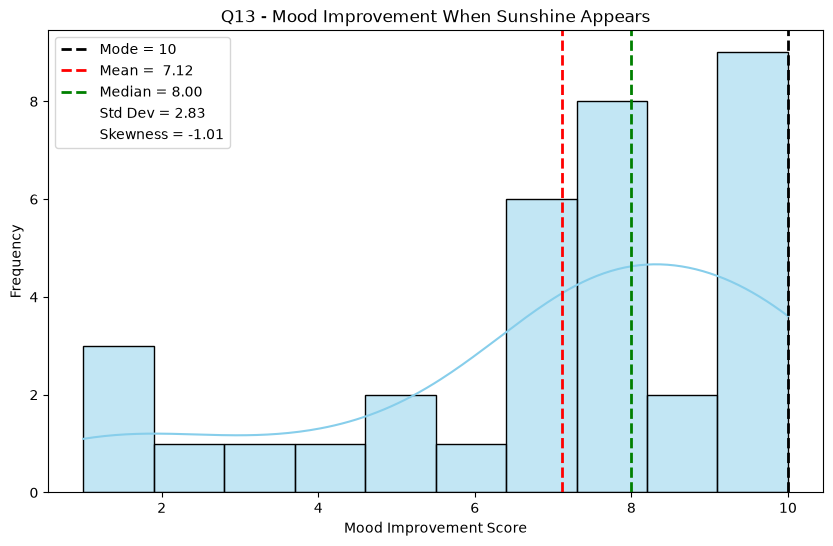

In [31]:
# Create the figure
plt.figure(figsize=(10,6))

#Calculate statistics
mean_q13 = q13.mean()
median_q13= q13.median()
mode_q13= q13.mode()[0] # Obtain the numerical value of the mode
stddev_q13= q13.std()
skew_q13= q13.skew()

sns.histplot(
    q13,
    bins=10,
    kde=True,
    color='skyblue'
    )

# Add mode line 
plt.axvline(
    mode_q13,
    color='black',
    linestyle='--',
    linewidth=2,
    label=f'Mode = {mode_q13}'
)
# Add mean line
plt.axvline(
    mean_q13,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean = {mean_q13: .2f}'
)
# Add median line
plt.axvline(
    median_q13,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median_q13:.2f}"
)

# Use empty lines to add std dev and skewness 
plt.plot([], [], ' ', label=f'Std Dev = {stddev_q13:.2f}')
plt.plot([], [], ' ', label=f'Skewness = {skew_q13:.2f}')

# Title and labels
plt.title("Q13 - Mood Improvement When Sunshine Appears")
plt.xlabel("Mood Improvement Score")
plt.ylabel("Frequency")

plt.legend()
plt.show()

# Graph 2
Q13
Target variable 

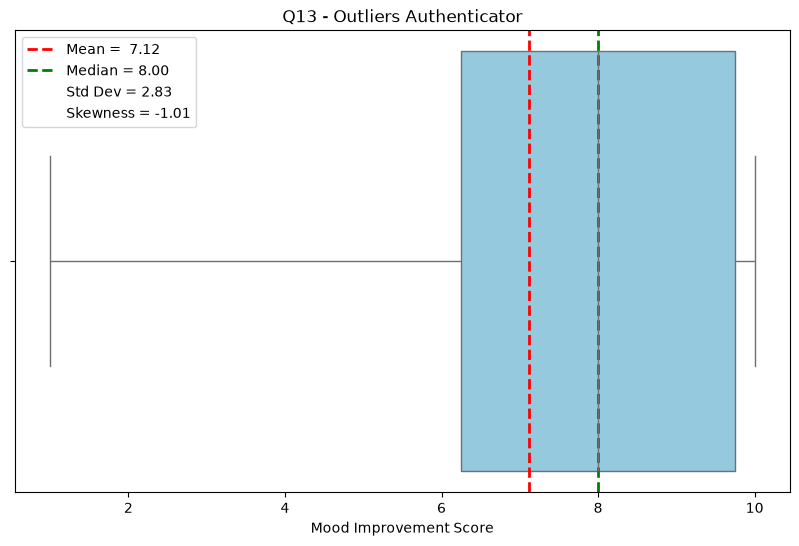

In [32]:
# Boxplot is used to identify the outlier
# Generate the figure size first

plt.figure(figsize=(10,6))
# Create the boxplot using seaborn
sns.boxplot(x=q13,color='skyblue')
# Add title and label names
plt.title('Q13 - Outliers Authenticator')
plt.xlabel('Mood Improvement Score')


plt.axvline(
    mean_q13,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean = {mean_q13: .2f}'
)
plt.axvline(
    median_q13,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median_q13:.2f}"
)

# Use empty lines to add std dev and skewness 
plt.plot([], [], ' ', label=f'Std Dev = {stddev_q13:.2f}')
plt.plot([], [], ' ', label=f'Skewness = {skew_q13:.2f}')

# Show the boxplot
plt.legend()
plt.show()


# Graph 3
Q13 <-> Q5 
Mood improvement <-> Energy Level on a gray day

Hypothesis:
Las personas con menos energía en días grises podrían experimentar una mayor mejora del estado de ánimo cuando aparece el sol.

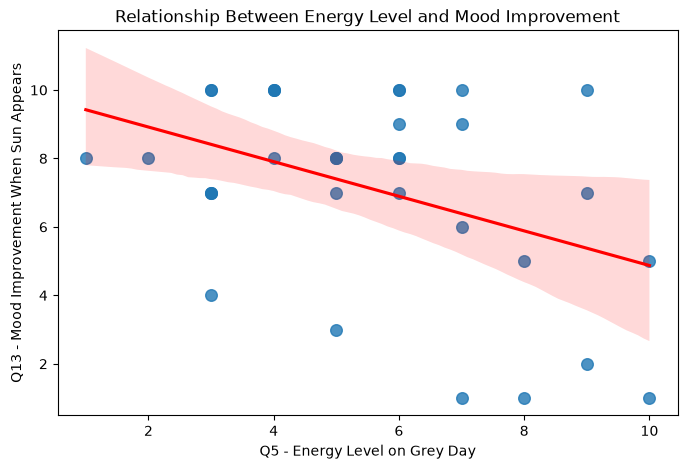

In [33]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df_renamed,
    x='Q5',
    y='Q13',
    scatter_kws={'s':70},
    line_kws={'color':'red'}
)

plt.title('Relationship Between Energy Level and Mood Improvement')
plt.xlabel('Q5 - Energy Level on Grey Day')
plt.ylabel('Q13 - Mood Improvement When Sun Appears')

plt.show()

The scatter plot suggests a weak negative relationship between energy levels on grey days (Q5) and mood improvement when the sun appears (Q13). Participants who reported lower energy levels during grey weather tended to experience a greater mood improvement when sunny conditions occurred, although considerable variability is present in the data.

C:\Users\35383\AppData\Local\Temp\ipykernel_18164\1968799230.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


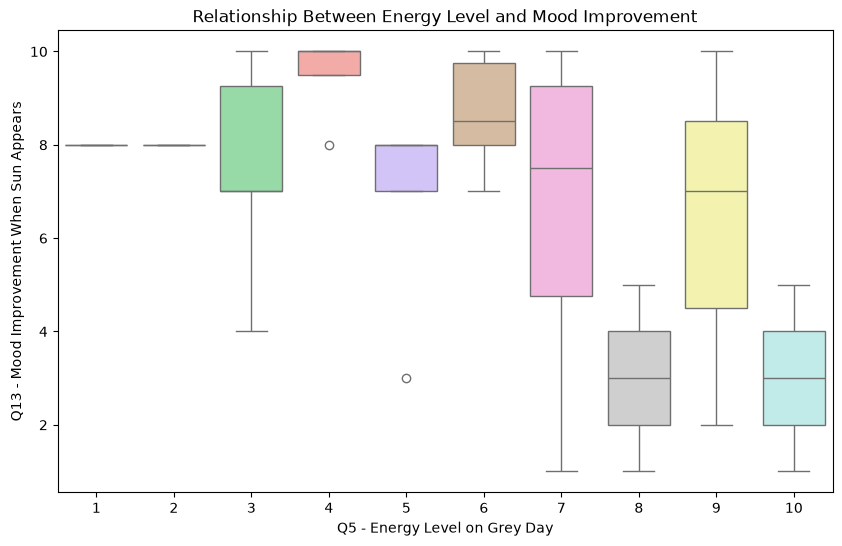

In [34]:
# Boxplot to explain this correlation

plt.figure(figsize=(10,6))
sns.boxplot(
    x='Q5',
    y='Q13',
    data=df_renamed,
    palette='pastel',
    legend=False
    
)
plt.title('Relationship Between Energy Level and Mood Improvement')
plt.xlabel('Q5 - Energy Level on Grey Day')
plt.ylabel('Q13 - Mood Improvement When Sun Appears')
plt.show()

Tabla con todas las relaciones de Q13 antes de comenzar con el estudio descriptivo

In [35]:
variables = ['Q4','Q5','Q9','Q10','Q12','Q14']

for var in variables:
    print("\n", var)
    print(pd.pivot_table(
            df_renamed,
            values='Q13',
            index=var,
            aggfunc=['mean','count']
        )
    )


 Q4
             mean count
              Q13   Q13
Q4                     
18 - 24  2.000000     1
25 - 34  6.529412    17
35 - 44  8.142857    14
45 +     7.500000     2

 Q5
        mean count
         Q13   Q13
Q5                
1   8.000000     1
2   8.000000     1
3   7.500000     6
4   9.500000     4
5   6.800000     5
6   8.666667     6
7   6.500000     4
8   3.000000     2
9   6.333333     3
10  3.000000     2

 Q9
        mean count
         Q13   Q13
Q9                
0   8.000000     3
1   5.777778     9
2   7.812500    16
3   6.800000     5
4   7.000000     1

 Q10
         mean count
          Q13   Q13
Q10                
0.0  6.642857    14
1.0  5.000000     4
2.0  7.250000     4
3.0  9.000000     5
4.0  8.750000     4
5.0  6.666667     3

 Q12
                                        mean count
                                         Q13   Q13
Q12                                               
None, my motivation stays the same  4.833333     6
☀️ Summer             

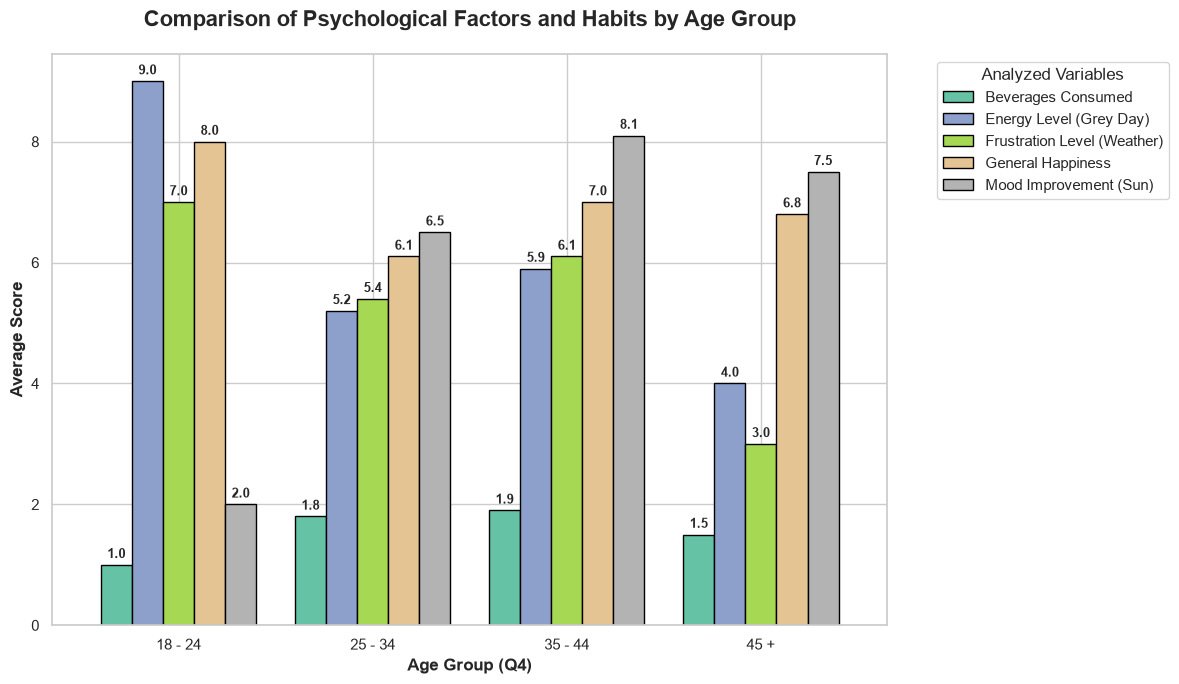

In [71]:
# Plot the pivot table (using only the 'mean' level to avoid multi-level errors)
sns.set_theme(style="whitegrid")

# We use pivot_friendly['mean'] to select only the averages
ax = pivot_friendly['mean'].plot(
    kind='bar',
    figsize=(12, 7),
    colormap='Set2',
    edgecolor='black',
    width=0.8
)

# Customization of titles and labels
plt.title('Comparison of Psychological Factors and Habits by Age Group', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Age Group (Q4)', fontsize=12, fontweight='bold')
plt.ylabel('Average Score', fontsize=12, fontweight='bold')
plt.xticks(rotation=0) # Keeps age labels horizontal

# Add exact values on top of each bar for high-precision reading
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9, fontweight='bold')

# Adjust legend so it doesn't cover the bars
plt.legend(title='Analyzed Variables', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# Graph 5
Q13 <->Q14 Mood imporvement <-> General Happiness under Weather Conditions

**Hipotesis:**

Las personas con mayores niveles de felicidad general (Q14) tienden a reportar una mayor mejora en su estado de ánimo cuando aparece el sol (Q13).

# Pivot Table de esta correlacion

In [36]:
# Se usa pandas para el pivot table
pd.pivot_table(
    data=df_renamed,
    values='Q13',
    index='Q14',
    aggfunc=['count','mean', 'median', 'std', 'var', 'skew']
)

,count,mean,median,std,var,skew
,Q13,Q13,Q13,Q13,Q13,Q13
Q14,,,,,,
1.0000,1,1.000000,1.0,NaN,NaN,NaN
2.0000,1,8.000000,8.0,NaN,NaN,NaN
3.0000,1,7.000000,7.0,NaN,NaN,NaN
5.0000,8,6.125000,6.5,3.356763,11.267857,-0.234642
6.0000,3,8.666667,8.0,1.154701,1.333333,1.732051
6.5625,2,8.000000,8.0,0.000000,0.000000,NaN
7.0000,6,7.500000,7.0,1.760682,3.100000,0.164892
8.0000,6,7.500000,8.5,3.082207,9.500000,-1.383151


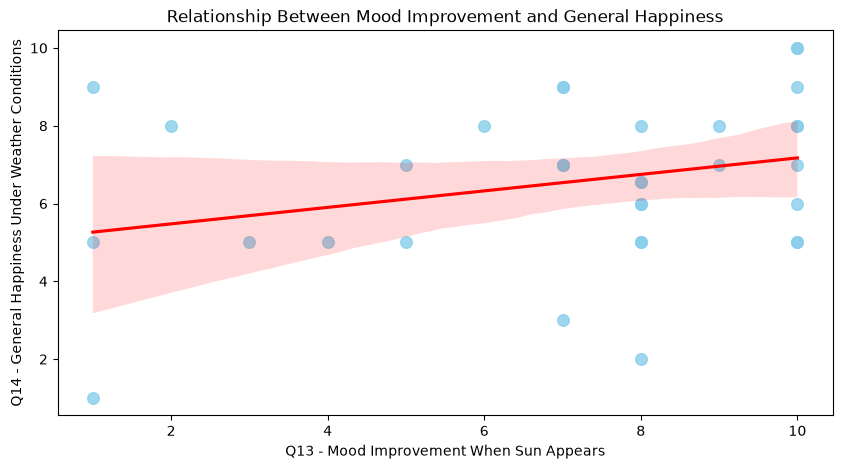

In [37]:
# Scatterplot
plt.figure(figsize=(10,5))

sns.regplot(
    data=df_renamed,
    x='Q13',
    y='Q14',
    scatter_kws= {'s': 70},
    color='skyblue',
    line_kws={'color':'red'}

)

plt.title('Relationship Between Mood Improvement and General Happiness')
plt.xlabel('Q13 - Mood Improvement When Sun Appears')
plt.ylabel('Q14 - General Happiness Under Weather Conditions')

plt.show()    
    

The graph suggests a positive relationship between Q13 and Q14. Individuals who experience a stronger mood improvement when the sun appears generally report higher overall happiness levels.

# Graph 6 
Q13 <->Q14 Mood imporvement <-> General Happiness under Weather Conditions   
Heatmap

In [38]:
heat_map=pd.crosstab(df_renamed['Q14'],df_renamed['Q13'])
print(heat_map)

Q13      1   2   3   4   5   6   7   8   9   10
Q14                                            
1.0000    1   0   0   0   0   0   0   0   0   0
2.0000    0   0   0   0   0   0   0   1   0   0
3.0000    0   0   0   0   0   0   1   0   0   0
5.0000    1   0   1   1   1   0   0   2   0   2
6.0000    0   0   0   0   0   0   0   2   0   1
6.5625    0   0   0   0   0   0   0   2   0   0
7.0000    0   0   0   0   1   0   3   0   1   1
8.0000    0   1   0   0   0   1   0   1   1   2
9.0000    1   0   0   0   0   0   2   0   0   1
10.0000   0   0   0   0   0   0   0   0   0   2


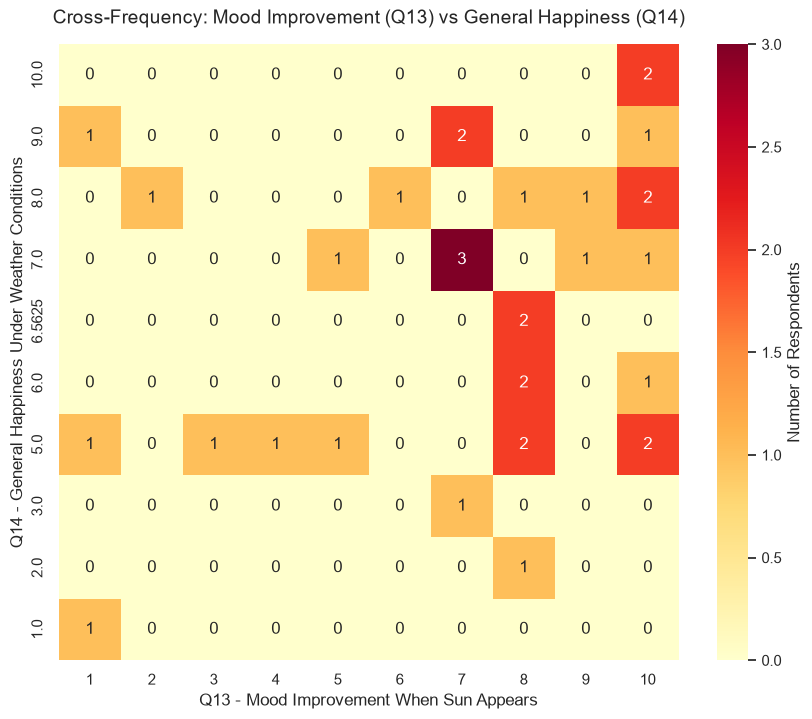

In [72]:
# Heat map
heatmap_data = pd.crosstab(df_renamed["Q14"], df_renamed["Q13"])

# 2. Configure figure size
plt.figure(figsize=(10, 8))

# 3. Plot the heatmap
# 'annot=True' displays the exact count of respondents in each cell
# 'fmt="d"' ensures the values are displayed as integers
# 'cmap="YlOrRd"' applies a highly visual Yellow-Orange-Red color palette
sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="YlOrRd", cbar_kws={'label': 'Number of Respondents'})

plt.title(
    "Cross-Frequency: Mood Improvement (Q13) vs General Happiness (Q14)",
    fontsize=14,
    pad=15,
)
plt.xlabel("Q13 - Mood Improvement When Sun Appears", fontsize=12)
plt.ylabel("Q14 - General Happiness Under Weather Conditions", fontsize=12)

# 4. Invert the Y-axis so that the highest values (10) are at the top
plt.gca().invert_yaxis()

plt.show()

The heatmap indicates that most responses are concentrated at high values of both Q13 and Q14. This suggests that participants experiencing greater mood improvement when sunny weather appears tend to report higher overall happiness levels.

# Graph 7

Q10 ↔ Q13

Bus Exposure per Week ↔ Mood Improvement When Sun Appears

hypothesis

Individuals with greater exposure to outdoor weather conditions through bus travel may report greater mood improvement when sunny weather appears.

# Pivot table de esta correlacion

In [40]:
# Use of pandas for a pivot table
pd.pivot_table(
    data=df_renamed,
    values='Q13',
    index='Q14',
    aggfunc=['count','mean', 'median']
)

,count,mean,median
,Q13,Q13,Q13
Q14,,,
1.0000,1,1.000000,1.0
2.0000,1,8.000000,8.0
3.0000,1,7.000000,7.0
5.0000,8,6.125000,6.5
6.0000,3,8.666667,8.0
6.5625,2,8.000000,8.0
7.0000,6,7.500000,7.0
8.0000,6,7.500000,8.5


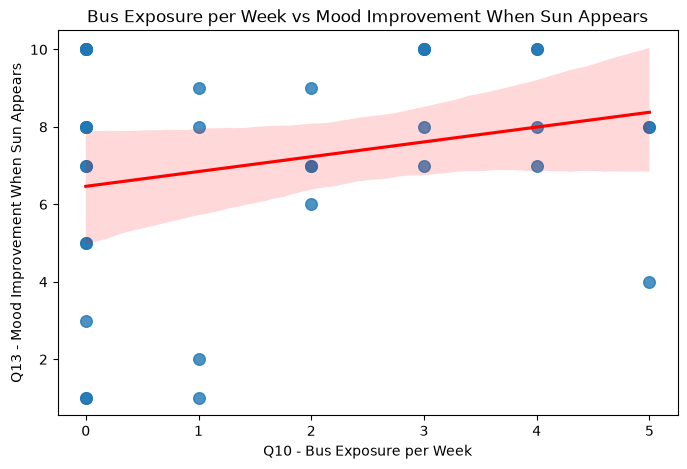

In [41]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df_renamed,
    x='Q10',
    y='Q13',
    scatter_kws={'s':70},
    line_kws={'color':'red'}
)

plt.title('Bus Exposure per Week vs Mood Improvement When Sun Appears')
plt.xlabel('Q10 - Bus Exposure per Week')
plt.ylabel('Q13 - Mood Improvement When Sun Appears')

plt.show()

The greater an individual's weekly weather exposure, the higher the positive impact when the sun appears.

# Graph 8

Q13 <-> Q12 Season of Motivation Drop (categórica) <-> Mood Improvement (numérica)

Pivot Table of the correlation

In [42]:
q12_q13 = pd.pivot_table(
    df_renamed,
    values='Q13',
    index='Q12',
    aggfunc=['count','mean','median','std','skew']
)
q12_q13

,count,mean,median,std,skew
,Q13,Q13,Q13,Q13,Q13
Q12,,,,,
"None, my motivation stays the same",6,4.833333,5.0,3.188521,-0.106941
☀️ Summer,11,7.636364,8.0,2.873072,-1.285418
❄️ Winter,12,7.833333,8.0,2.622744,-1.814691
🌱 Spring,3,6.666667,7.0,2.516611,-0.585583
🍂Autumn,2,7.500000,7.5,0.707107,NaN


People whose motivation drops during different seasons may experience different levels of mood improvement when sunny weather appears.

# Graph 9 
Q13<->Q12

C:\Users\35383\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127793 (\N{SEEDLING}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\35383\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127810 (\N{FALLEN LEAF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


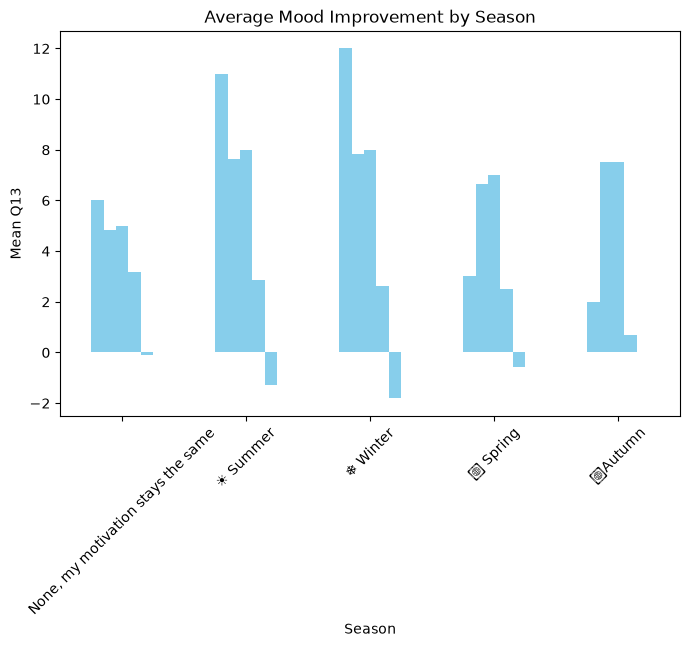

In [43]:
# Bar chart
q12_q13.plot(
    kind='bar',
    figsize=(8,5),
    legend=False,
    color='skyblue'
)

plt.title('Average Mood Improvement by Season')
plt.xlabel('Season')
plt.ylabel('Mean Q13')
plt.xticks(rotation=45)
plt.show()

The bar chart shows the average mood improvement score (Q13) for respondents based on the season in which they experience the greatest drop in motivation (Q12). Participants who reported that their motivation remains the same throughout the year showed the lowest average mood improvement score. In contrast, participants identifying Winter, Summer, Autumn, or Spring as periods of reduced motivation reported higher average mood improvement scores, generally ranging between 6.5 and 8. This suggests that individuals who experience seasonal fluctuations in motivation may be more sensitive to positive changes in weather conditions.

# Graph 10
Q4 Age Range
Most respondents belonged to the 25-34 age group, while the 18-24 age group had the lowest representation

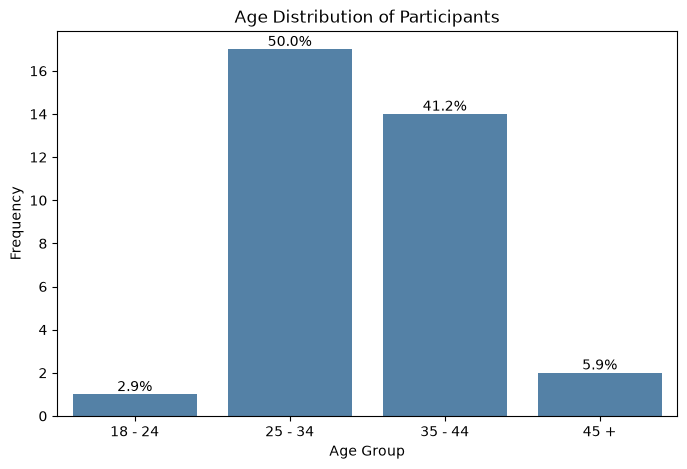

In [44]:
plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df_renamed,
    x='Q4',
    order=['18 - 24', '25 - 34', '35 - 44', '45 +'],
    color='steelblue'
)

total = len(df_renamed)

for p in ax.patches:
    count = int(p.get_height())
    percentage = 100 * count / total

    ax.annotate(
        f'{percentage:.1f}%',
        (p.get_x() + p.get_width()/2, count),
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title('Age Distribution of Participants')
plt.xlabel('Age Group')
plt.ylabel('Frequency')

plt.show()

# Pivot Table by age and correlation with several questions

In [62]:
# 1. Define friendly and descriptive names for our columns of interest
friendly_names = {
    'Q3': 'Frustration Level (Weather)',
    'Q5': 'Energy Level (Grey Day)',
    'Q9': 'Beverages Consumed',
    'Q13': 'Mood Improvement (Sun)',
    'Q14': 'General Happiness'
}

# 2. Create a temporary copy with the renamed columns
df_temp = df_renamed.rename(columns=friendly_names)

# 3. Create the pivot table using the new, more descriptive names
pivot_friendly = pd.pivot_table(
    df_temp,
    index='Q4',  # Grouped by Age
    values=list(friendly_names.values()),
    aggfunc=['mean', 'count']
)

# 4. Round to 1 decimal place to improve visual readability
pivot_friendly = pivot_friendly.round(1)

# Display the clean result
display(pivot_friendly)

mean                          \
        Beverages Consumed Energy Level (Grey Day)   
Q4                                                   
18 - 24                1.0                     9.0   
25 - 34                1.8                     5.2   
35 - 44                1.9                     5.9   
45 +                   1.5                     4.0   

                                                                              \
        Frustration Level (Weather) General Happiness Mood Improvement (Sun)   
Q4                                                                             
18 - 24                         7.0               8.0                    2.0   
25 - 34                         5.4               6.1                    6.5   
35 - 44                         6.1               7.0                    8.1   
45 +                            3.0               6.8                    7.5   

                     count                          \
        Beverages Consumed Energy Level (Grey Day)   
Q4                                                   
18 - 24                  1                       1   
25 - 34                 17                      17   
35 - 44                 14                      14   
45 +                     2                       2   

                                                                              
        Frustration Level (Weather) General Happiness Mood Improvement (Sun)  
Q4                                                                            
18 - 24                           1                 1                      1  
25 - 34                          17                17                     17  
35 - 44                          14                14                     14  
45 +                              2                 2                      2

In summary, while younger adults (25-34) struggle the most with grey days, middle-aged adults (35-44) benefit the most from sunshine. Future data collection should aim to include more respondents in the 18-24 and 45+ brackets to ensure valid comparisons.

# Graph 11

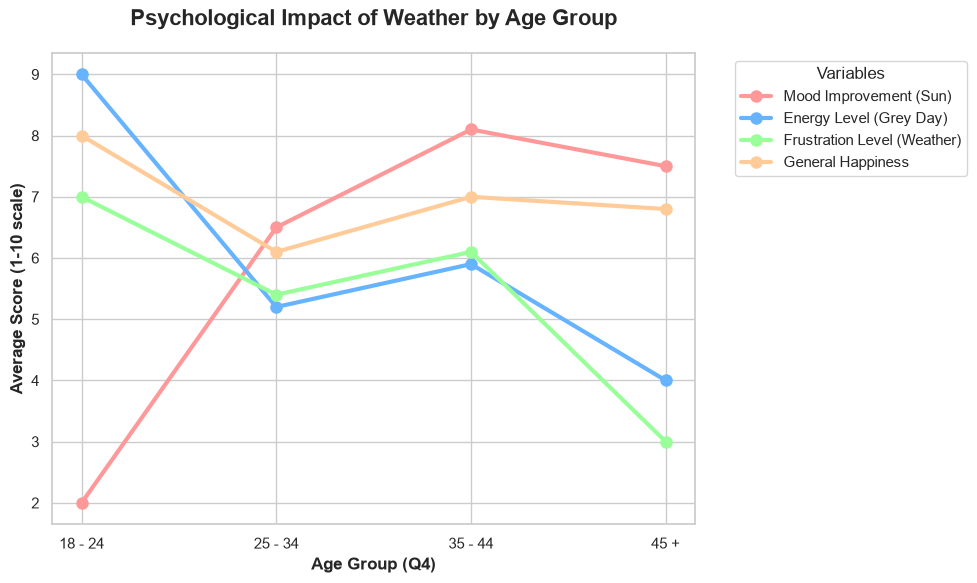

In [63]:
# 1. Select only the 4 variables that share a similar scale (1-10)
# We extract only the 'mean' level of our pivot table
vars_to_plot = [
    'Mood Improvement (Sun)', 
    'Energy Level (Grey Day)', 
    'Frustration Level (Weather)', 
    'General Happiness'
]

# Filter the pivot table to only include these 4 columns
data_to_plot = pivot_friendly['mean'][vars_to_plot]

# 2. Set the visual style (Clean and professional)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# 3. Plot the lines
# We use a color palette that contrasts well
colors = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']
for i, column in enumerate(data_to_plot.columns):
    plt.plot(data_to_plot.index, data_to_plot[column], 
             marker='o', markersize=8, linewidth=3, label=column, color=colors[i])

# 4. Customize the chart
plt.title('Psychological Impact of Weather by Age Group', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Age Group (Q4)', fontsize=12, fontweight='bold')
plt.ylabel('Average Score (1-10 scale)', fontsize=12, fontweight='bold')
plt.legend(title='Variables', bbox_to_anchor=(1.05, 1), loc='upper left') # Legend outside

# Adjust layout so the legend doesn't get cut off
plt.tight_layout()

# 5. Show the chart
plt.show()

# Graph 12

# Normal distribution 

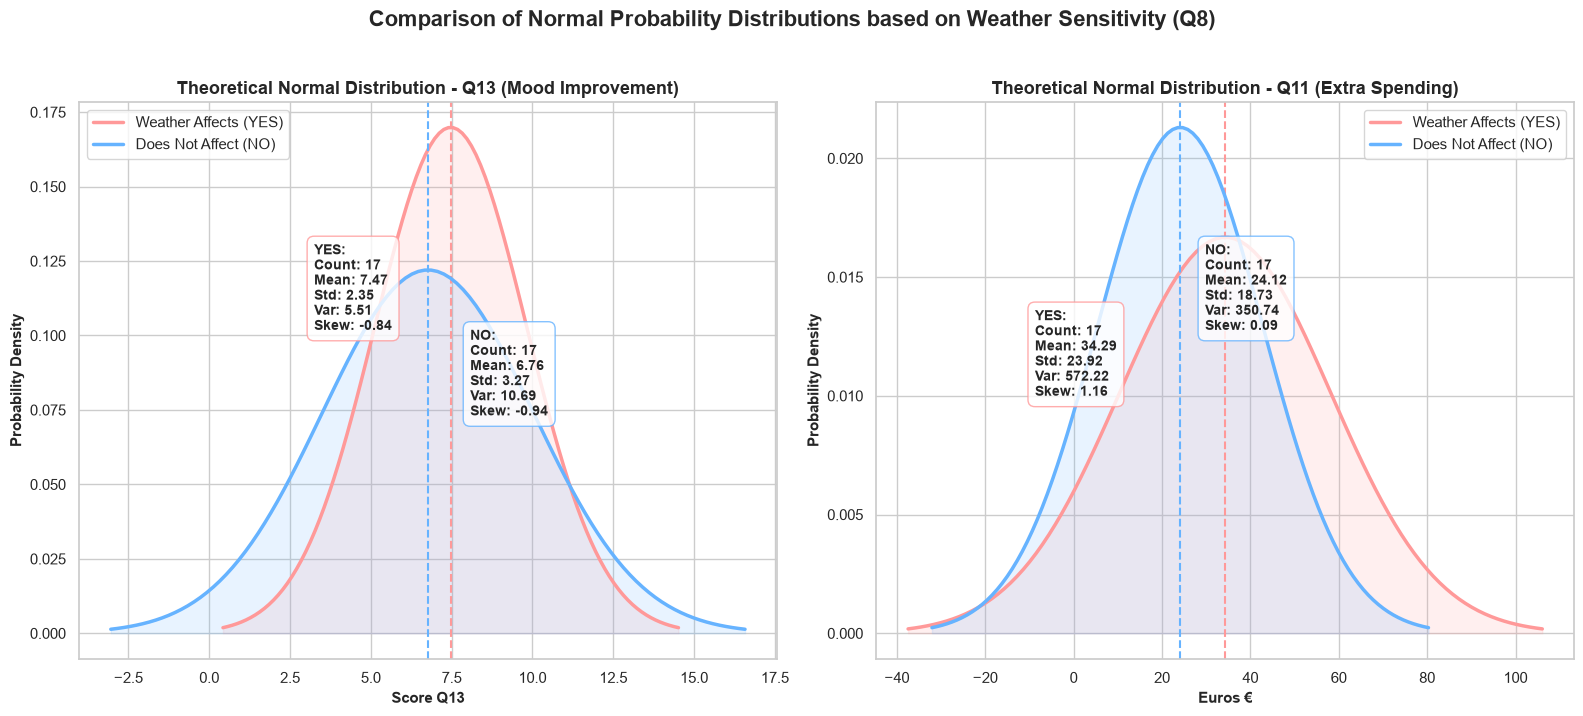

In [69]:
# 1. Set the visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Define the groups and their colors
groups = [('YES', '#ff9999', 'Weather Affects (YES)'), ('NO', '#66b3ff', 'Does Not Affect (NO)')]

# --- PANEL 1: Q13 (Mood Improvement) ---
ax1 = axes[0]
for q8_val, color, label in groups:
    # Extract actual data from the group to calculate precise statistics
    data_group = group_yes['Q13'] if q8_val == 'YES' else group_no['Q13']
    
    # Calculate requested statistics
    n = len(data_group)
    mu_val = data_group.mean()
    std_val = data_group.std()
    var_val = data_group.var()
    skew_val = data_group.skew()
    
    # Generate the theoretical normal distribution curve
    x_axis = np.linspace(mu_val - 3*std_val, mu_val + 3*std_val, 100)
    y_axis = norm.pdf(x_axis, mu_val, std_val)
    
    # Plot the curve and the mean line
    ax1.plot(x_axis, y_axis, color=color, linewidth=2.5, label=label)
    ax1.fill_between(x_axis, y_axis, color=color, alpha=0.15)
    ax1.axvline(mu_val, color=color, linestyle='--', linewidth=1.5)
    
    # Position text boxes with statistics
    box_x = mu_val - 1.8 * std_val if q8_val == 'YES' else mu_val + 0.4 * std_val
    stats_text = (f"{q8_val}:\n"
                  f"Count: {n}\n"
                  f"Mean: {mu_val:.2f}\n"
                  f"Std: {std_val:.2f}\n"
                  f"Var: {var_val:.2f}\n"
                  f"Skew: {skew_val:.2f}")
    ax1.text(box_x, max(y_axis)*0.6, stats_text, fontsize=10, fontweight='bold', 
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor=color))

ax1.set_title('Theoretical Normal Distribution - Q13 (Mood Improvement)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Score Q13', fontsize=11, fontweight='bold')
ax1.set_ylabel('Probability Density', fontsize=11, fontweight='bold')
ax1.legend(loc='upper left')

# --- PANEL 2: Q11 (Extra Spending) ---
ax2 = axes[1]
for q8_val, color, label in groups: # <-- OJO: Cámbialo a 'groups'
    # Extract actual Q11_numeric data
    data_group = group_yes['Q11_numeric'] if q8_val == 'YES' else group_no['Q11_numeric']
    
    # Calculate requested statistics
    n = len(data_group)
    mu_val = data_group.mean()
    std_val = data_group.std()
    var_val = data_group.var()
    skew_val = data_group.skew()
    
    # Generate the theoretical normal distribution curve
    x_axis = np.linspace(mu_val - 3*std_val, mu_val + 3*std_val, 100)
    y_axis = norm.pdf(x_axis, mu_val, std_val)
    
    # Plot the curve and the mean line
    ax2.plot(x_axis, y_axis, color=color, linewidth=2.5, label=label)
    ax2.fill_between(x_axis, y_axis, color=color, alpha=0.15)
    ax2.axvline(mu_val, color=color, linestyle='--', linewidth=1.5)
    
    # Position text boxes with statistics
    box_x = mu_val - 1.8 * std_val if q8_val == 'YES' else mu_val + 0.3 * std_val
    stats_text = (f"{q8_val}:\n"
                  f"Count: {n}\n"
                  f"Mean: {mu_val:.2f}\n"
                  f"Std: {std_val:.2f}\n"
                  f"Var: {var_val:.2f}\n"
                  f"Skew: {skew_val:.2f}")
    ax2.text(box_x, max(y_axis)*0.6, stats_text, fontsize=10, fontweight='bold', 
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor=color))

ax2.set_title('Theoretical Normal Distribution - Q11 (Extra Spending)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Euros €', fontsize=11, fontweight='bold')
ax2.set_ylabel('Probability Density', fontsize=11, fontweight='bold')
ax2.legend(loc='upper right')

plt.suptitle('Comparison of Normal Probability Distributions based on Weather Sensitivity (Q8)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Graph 13
Q13 <-> Q4
Age Range (ordinal) <->  Q13: Mood Improvement When Sun Appears (target)

In [45]:
# Create a pivot table

age_q13=pd.pivot_table(
    df_renamed,
    values='Q13',
    index='Q4',
    aggfunc=['count','mean','median']
)
age_q13

,count,mean,median
,Q13,Q13,Q13
Q4,,,
18 - 24,1,2.000000,2.0
25 - 34,17,6.529412,8.0
35 - 44,14,8.142857,9.0
45 +,2,7.500000,7.5


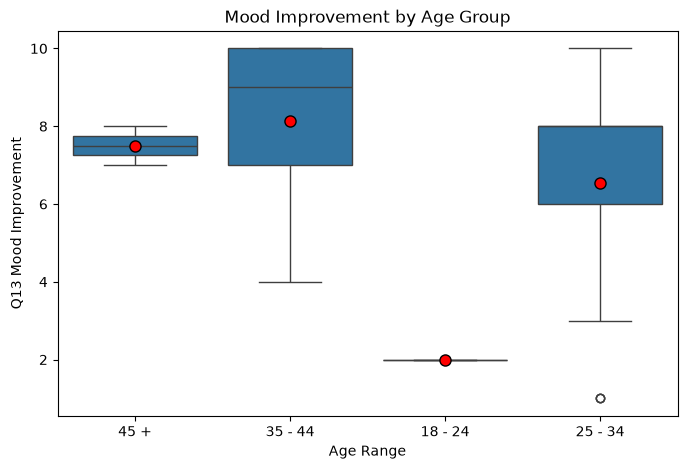

In [46]:
# Boxplot so we can see the outliers 
order = ['18-24', '25-34', '35-44', '45+']
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_renamed,
    x='Q4',
    y='Q13',
    
    showmeans=True,
    meanprops={
        'marker':'o',
        'markerfacecolor':'red',
        'markeredgecolor':'black',
        'markersize':8
    }
)

plt.title('Mood Improvement by Age Group')
plt.xlabel('Age Range')
plt.ylabel('Q13 Mood Improvement')

plt.show()

# Graph 14

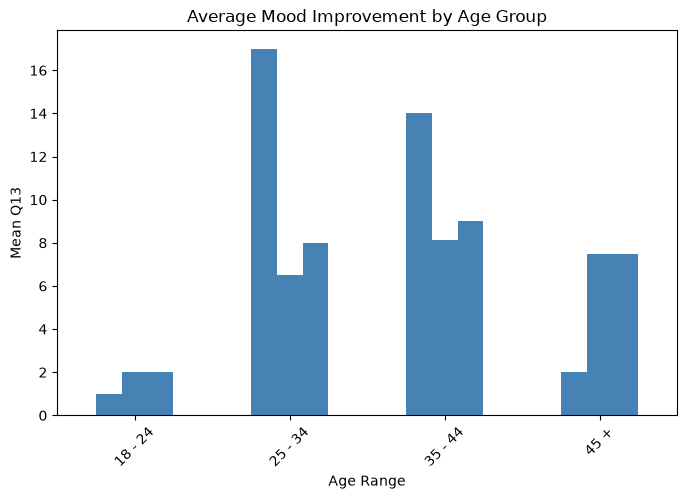

In [47]:
age_q13.plot(
    kind='bar',
    figsize=(8,5),
    color='steelblue',
    legend=False
)

plt.title('Average Mood Improvement by Age Group')
plt.xlabel('Age Range')
plt.ylabel('Mean Q13')
plt.xticks(rotation=45)

plt.show()

# Graph 15
Q13<->Q9+Q4 Number of beverages used to lift mood <-> Mood improvement when sun appears

Hypothesis:

Do the age groups that consume more mood-enhancing beverages also report a greater improvement in mood when the sun comes out?

In [48]:
summary = pd.pivot_table(
    df_renamed,
    index='Q4',
    values=['Q13','Q9'],
    aggfunc=['count','mean','median']
)
summary

count          mean           median     
          Q13  Q9       Q13        Q9    Q13   Q9
Q4                                               
18 - 24     1   1  2.000000  1.000000    2.0  1.0
25 - 34    17  17  6.529412  1.764706    8.0  2.0
35 - 44    14  14  8.142857  1.857143    9.0  2.0
45 +        2   2  7.500000  1.500000    7.5  1.5

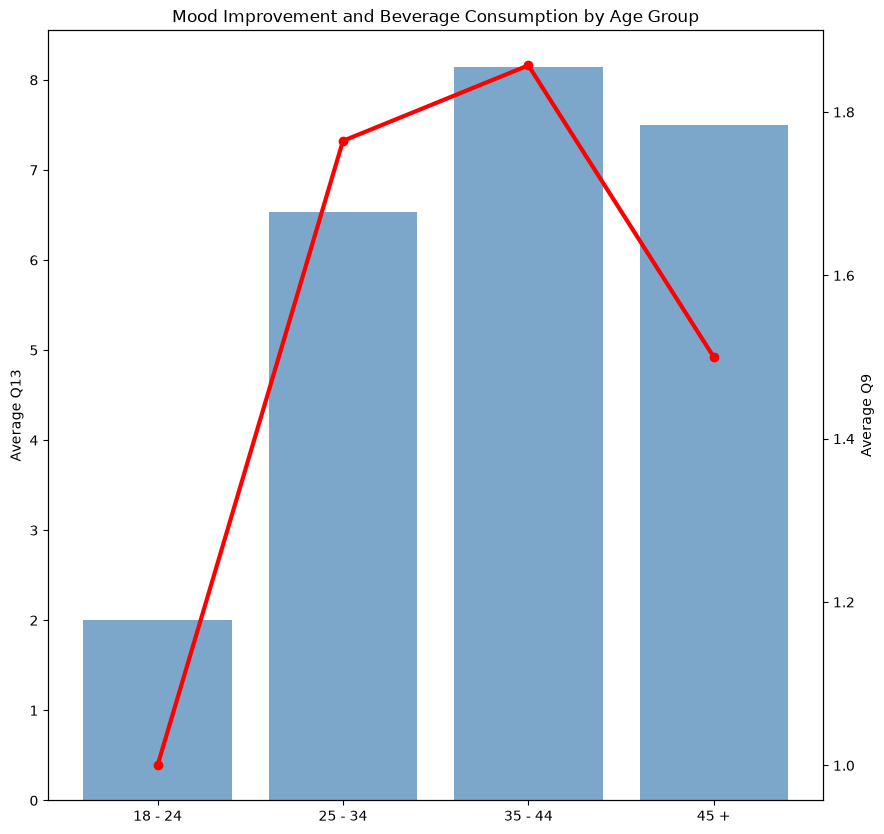

In [49]:
fig, ax1 = plt.subplots(figsize=(10,10))

ax1.bar(
    summary.index,
    summary[('mean','Q13')],
    color='steelblue',
    alpha=0.7,
    label='Mood Improvement'
)

ax1.set_ylabel('Average Q13')

ax2 = ax1.twinx()

ax2.plot(
    summary.index,
    summary[('mean','Q9')],
    color='red',
    marker='o',
    linewidth=3
)

ax2.set_ylabel('Average Q9')

plt.title('Mood Improvement and Beverage Consumption by Age Group')

plt.show()

The 35–44 age group showed the strongest mood improvement when sunshine appeared, whereas respondents aged 18–24 reported the weakest response. Beverage consumption generally increased alongside mood improvement across the age groups analysed.

# Graph 16
Q13<->Q5 Mood improvement when sun appears <-> Energy Level on a gray day

In [50]:
# Pivot Table - cuenta la historia antes de graficar
pd.pivot_table(
    df_renamed,
    index='Q5',
    values='Q13',
    aggfunc=['count','mean','median']
)

,count,mean,median
,Q13,Q13,Q13
Q5,,,
1,1,8.000000,8.0
2,1,8.000000,8.0
3,6,7.500000,7.0
4,4,9.500000,10.0
5,5,6.800000,8.0
6,6,8.666667,8.5
7,4,6.500000,7.5
8,2,3.000000,3.0


Participants with lower or moderate energy levels on grey days appear to report a stronger mood improvement when sunshine appears, whereas respondents with very high energy levels tend to report a smaller emotional change.

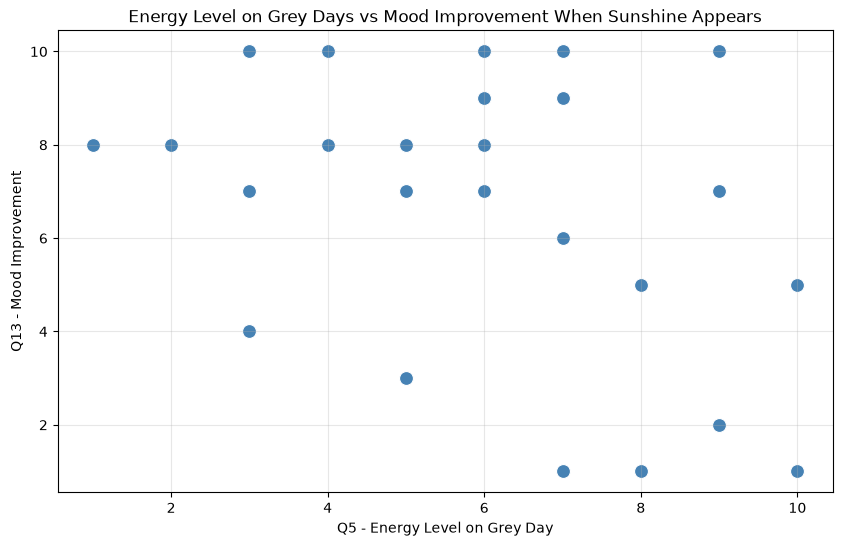

In [51]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df_renamed,
    x='Q5',
    y='Q13',
    s=100,
    color='steelblue',
    
)

plt.title('Energy Level on Grey Days vs Mood Improvement When Sunshine Appears')
plt.xlabel('Q5 - Energy Level on Grey Day')
plt.ylabel('Q13 - Mood Improvement')

plt.grid(alpha=0.3)
plt.show()

# Pearson

Pearson correlation coefficient (often denoted as r). It measures two things at the same time: The Strength and The Direction of a linear relationship between two variables.

In [52]:
df_renamed['Q5'].corr(df_renamed['Q13'])

np.float64(-0.4184574520090169)

A moderate negative correlation (-0.418) was observed between energy levels on grey days (Q5) and mood improvement when sunshine appeared (Q13). This suggests that respondents with lower energy levels during overcast weather tended to report a greater emotional improvement when sunshine appeared, although the relationship was not particularly strong.

# Graph 17

Q8 <-> Q15 Productivity affected by rain <-> Pint gets forget the weather

In [53]:
# Pivot Table to check aggregation function

pd.pivot_table(
    df_renamed,
    index='Q8',
    values='Q15',
    margins=True,
    aggfunc=['count','mean','median']
)

,count,mean,median
,Q15,Q15,Q15
Q8,,,
NO,17,0.294118,0.0
YES,17,0.235294,0.0
All,34,0.264706,0.0


In [54]:
# As we got median of 0, created the crosstab to check all number of options respond by people
pd.crosstab(df_renamed['Q8'], df_renamed['Q15'], margins=True)

Q15,False,True,All
Q8,,,
NO,12,5,17
YES,13,4,17
All,25,9,34


<Axes: xlabel='Q8'>

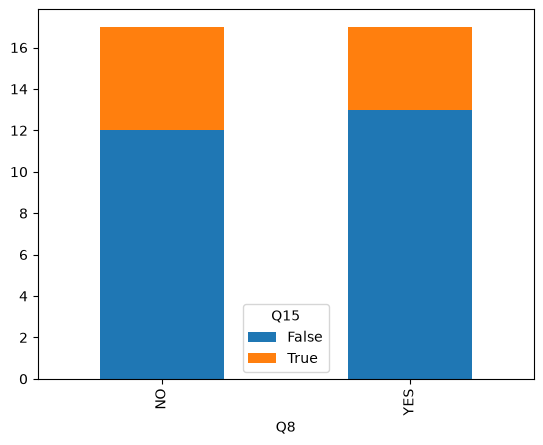

In [55]:
pd.crosstab(df_renamed['Q8'], df_renamed['Q15']).plot(kind='bar', stacked=True)

# Graph 18

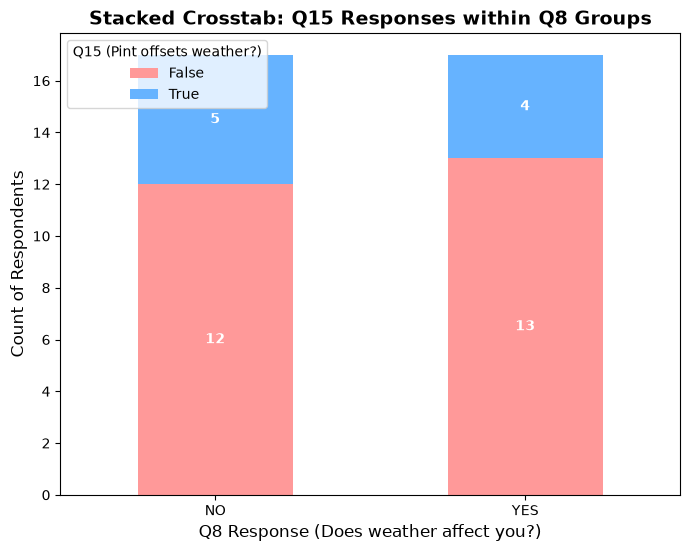

In [56]:
import matplotlib.pyplot as plt

# 1. Creamos la gráfica y la guardamos en la variable 'ax'
ax = pd.crosstab(df_renamed['Q8'], df_renamed['Q15']).plot(
    kind='bar', 
    stacked=True, 
    color=['#ff9999', '#66b3ff'], 
    figsize=(8,6)
)

# 2. Le ponemos el título principal
plt.title('Stacked Crosstab: Q15 Responses within Q8 Groups', fontsize=14, fontweight='bold')

# 3. Etiquetas de los ejes
plt.xlabel('Q8 Response (Does weather affect you?)', fontsize=12)
plt.ylabel('Count of Respondents', fontsize=12)
plt.xticks(rotation=0) # Para que NO y YES se lean derechito

# 4. Leyenda
plt.legend(title='Q15 (Pint offsets weather?)', labels=['False', 'True'])

# 5. (Opcional) Añadir los números exactos dentro de las barras
# Como están apiladas, es un poco más de código, pero queda increíble
for c in ax.containers:
    ax.bar_label(c, label_type='center', fontweight='bold', color='white')

plt.show()

Overall, most respondents do not believe that having a pint in a pub completely offsets the effects of the weather: 25 out of 34 (73%) selected False, compared to only 9 who selected True. Interestingly, this trend is consistent across both Q8 groups. In the 'NO' group, 12 chose False vs 5 True, and in the 'YES' group, 13 chose False vs 4 True. This suggests that the belief in Q15 is independent of the response to Q8.

# Pearson

In [57]:
# In order to obtain the pearson index we have to convert the Yes-No to a number
_q8_numeric = df_renamed['Q8'].replace({'YES': 1, 'NO': 0})
_q15_numeric = df_renamed['Q15'].astype(int)

# Obtain the correlation between this two questions
_q8_numeric.corr(_q15_numeric)

np.float64(-0.06666666666666668)

There is almost no relationship between the two variables. The negative sign shows an inverse trend, but the magnitude is too small to be of practical relevance.


# Bayes' theorem   , Graph 19 - 20

Bayes' theorem, named after Thomas Bayes, gives a mathematical rule for inverting conditional probabilities, allowing the probability of a cause to be found given its effect.

In [58]:
# --- 1. DATA PREPARATION ---
# Assuming df_renamed already contains your data
# We will normalize (convert to proportions) the dataset for the probability test
df_norm = df_renamed[['Q8', 'Q15']].copy()

# Calculate totals (N)
N_total = len(df_norm)

print("=== 1. CALCULATING PRIORS (Initial Probabilities) ===")
# P(A) - Probability that weather affects them (Q8 = YES)
p_yes = len(df_norm[df_norm['Q8'] == 'YES']) / N_total
p_no = len(df_norm[df_norm['Q8'] == 'NO']) / N_total

# P(B) - Probability they believe a pint doesn't offset the cold (Q15 = False)
p_false = len(df_norm[df_norm['Q15'] == False]) / N_total
p_true = len(df_norm[df_norm['Q15'] == True]) / N_total

print(f"Prior P(Q8 = YES): {p_yes:.4f} ({p_yes*100:.2f}%)")
print(f"Prior P(Q8 = NO): {p_no:.4f} ({p_no*100:.2f}%)")
print(f"Prior P(Q15 = False): {p_false:.4f} ({p_false*100:.2f}%)")
print(f"Prior P(Q15 = True): {p_true:.4f} ({p_true*100:.2f}%)\n")

print("=== 2. CONDITIONAL PROBABILITY (Likelihoods) ===")
# P(B|A) - Probability of Q15=False given that Q8=YES
p_false_given_yes = len(df_norm[(df_norm['Q8'] == 'YES') & (df_norm['Q15'] == False)]) / len(df_norm[df_norm['Q8'] == 'YES'])
# P(B|A) - Probability of Q15=False given that Q8=NO
p_false_given_no = len(df_norm[(df_norm['Q8'] == 'NO') & (df_norm['Q15'] == False)]) / len(df_norm[df_norm['Q8'] == 'NO'])

print(f"P(Q15 = False | Q8 = YES): {p_false_given_yes:.4f} ({p_false_given_yes*100:.2f}%)")
print(f"P(Q15 = False | Q8 = NO): {p_false_given_no:.4f} ({p_false_given_no*100:.2f}%)\n")

print("=== 3. APPLYING BAYES' THEOREM (Posteriors) ===")
# P(A|B) - The probability that Q8=YES given that Q15=False
# Formula: P(A|B) = [P(B|A) * P(A)] / P(B)
p_yes_given_false = (p_false_given_yes * p_yes) / p_false

print(f"Bayesian Posterior P(Q8 = YES | Q15 = False): {p_yes_given_false:.4f} ({p_yes_given_false*100:.2f}%)")
print("-> This answers: If I know the person said 'False' about the pint, what is the probability that the weather actually affects them (YES)?")

=== 1. CALCULATING PRIORS (Initial Probabilities) ===
Prior P(Q8 = YES): 0.5000 (50.00%)
Prior P(Q8 = NO): 0.5000 (50.00%)
Prior P(Q15 = False): 0.7353 (73.53%)
Prior P(Q15 = True): 0.2647 (26.47%)

=== 2. CONDITIONAL PROBABILITY (Likelihoods) ===
P(Q15 = False | Q8 = YES): 0.7647 (76.47%)
P(Q15 = False | Q8 = NO): 0.7059 (70.59%)

=== 3. APPLYING BAYES' THEOREM (Posteriors) ===
Bayesian Posterior P(Q8 = YES | Q15 = False): 0.5200 (52.00%)
-> This answers: If I know the person said 'False' about the pint, what is the probability that the weather actually affects them (YES)?


Bayes' theorem was applied using Q8 (productivity affected by rainy mornings) and Q15 (belief that a pint helps offset the effects of weather). The posterior probability obtained was 52%, only slightly higher than the prior probability of 50%. This suggests that knowing whether a respondent believes a pint helps forget the weather adds little predictive information regarding whether rainy mornings affect their productivity.

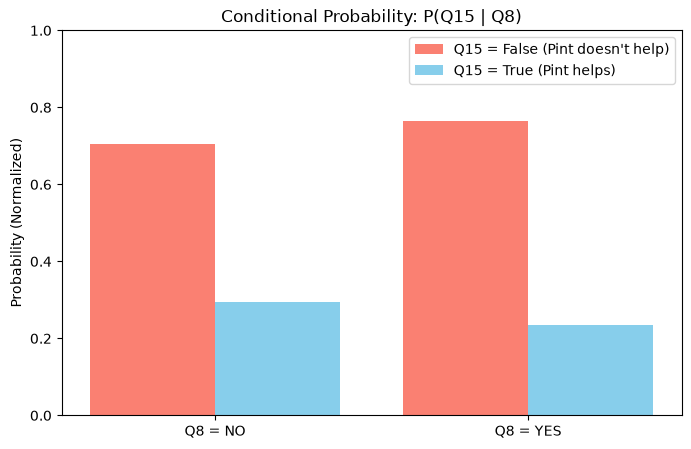

In [59]:
# Conditional probabilities chart (Normalized)
# We manually extract the probabilities to plot them
labels = ['Q8 = NO', 'Q8 = YES']
prob_false = [p_false_given_no, p_false_given_yes]
prob_true = [1 - p_false_given_no, 1 - p_false_given_yes]

x = range(len(labels))
plt.figure(figsize=(8, 5))
plt.bar([i - 0.2 for i in x], prob_false, width=0.4, label='Q15 = False (Pint doesn\'t help)', color='salmon')
plt.bar([i + 0.2 for i in x], prob_true, width=0.4, label='Q15 = True (Pint helps)', color='skyblue')

plt.ylabel('Probability (Normalized)')
plt.title('Conditional Probability: P(Q15 | Q8)')
plt.xticks(x, labels)
plt.ylim(0, 1) # Scale from 0 to 1
plt.legend()
plt.show()

# Graph 21

<Figure size 800x600 with 0 Axes>

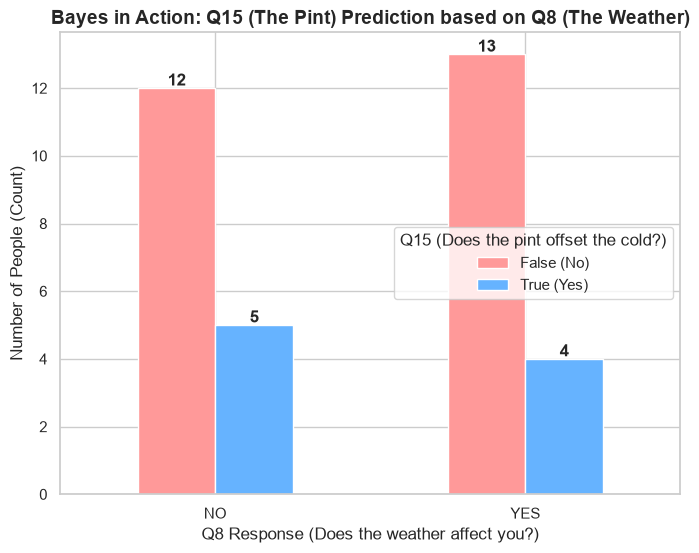

In [60]:
# 1. Prepare the data for the chart using the crosstab we already created
# We remove the 'All' row so we don't plot the total, only the NO and YES groups
tabla_grafico = pd.crosstab(df_renamed['Q8'], df_renamed['Q15']).drop(index='All', errors='ignore')

# 2. Set the visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 6))

# 3. Draw the grouped bars
# We use the transposed table (.T) so the bars are grouped by Q8
ax = tabla_grafico.plot(kind='bar', stacked=False, color=['#ff9999', '#66b3ff'], figsize=(8,6))

# 4. Customize titles and labels
plt.title('Bayes in Action: Q15 (The Pint) Prediction based on Q8 (The Weather)', fontsize=14, fontweight='bold')
plt.xlabel('Q8 Response (Does the weather affect you?)', fontsize=12)
plt.ylabel('Number of People (Count)', fontsize=12)
plt.xticks(rotation=0) # So NO and YES are read horizontally
plt.legend(title='Q15 (Does the pint offset the cold?)', labels=['False (No)', 'True (Yes)'])

# 5. Add the exact numbers on top of each bar (This is an expert-level touch!)
for p in ax.patches:
    ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.show()

# Graph 22
Q13<->Q8<->Q14
Q13<->Q8<->Q11
Q8 = Productivity affected by rain (YES/NO)
Q11 = Extra Spending $ on sunny days 
Q13 = Mood Improvement (1-10)

Hypothesis: Weather sensitivity (Q8) significantly alters the probability distribution of both mood improvement (Q13) and extra spending (Q11)

The Normal Distribution analysis provides profound insights into how weather sensitivity (Q8) shapes both mood and spending. Paradoxically, individuals who admit the weather affects them (YES) report higher and more consistent mood levels, suggesting greater emotional self-awareness. However, their spending behavior reveals a different story: while most weather-sensitive people are frugal, the positive skewness (1.16) indicates a subset of individuals who engage in extreme spending (potentially as 'retail therapy' on grey days). Conversely, the group unaffected by weather exhibits a higher average spending (€74.12) with a symmetrical distribution, implying a stable but higher baseline expenditure regardless of weather conditions

In [64]:
import re

print("=== P-NORM PROBABILITY TEST USING norm.cdf (Q8, Q13, Q11) ===\n")

# --- PREVIOUS CLEANING OF Q11 ---
# Create a working copy to avoid destructively altering the original DataFrame
df_cleaned = df_renamed.copy()

# Function to extract the first number from each text cell in Q11
def clean_money(val):
    if pd.isna(val):
        return None
    # Find digits in the text
    numbers = re.findall(r'\d+', str(val))
    if numbers:
        return float(numbers[0])
    return None

# Apply the cleaning function to Q11
df_cleaned['Q11_numeric'] = df_cleaned['Q11'].apply(clean_money)

# Impute the resulting null values from cleaning (e.g., texts like 'Same as a grey day') with the median
median_q11 = df_cleaned['Q11_numeric'].median()
df_cleaned['Q11_numeric'] = df_cleaned['Q11_numeric'].fillna(median_q11)

# 1. Split the dataset based on the categorical variable Q8
group_yes = df_cleaned[df_cleaned['Q8'] == 'YES']
group_no = df_cleaned[df_cleaned['Q8'] == 'NO']

# 2. Define the numerical variables to test (using the new clean Q11 column)
variables_to_test = ['Q13', 'Q11_numeric']

# 3. Define the target values for each variable
target_q13 = 5
target_q11 = df_cleaned['Q11_numeric'].mean()  # Now we can calculate the numerical mean of Q11

targets = {'Q13': target_q13, 'Q11_numeric': target_q11}

# Mapping of names to improve printing
print_names = {'Q13': 'Q13 (Mood Improvement)', 'Q11_numeric': 'Q11 (Extra Spending)'}

for var in variables_to_test:
    data_yes = group_yes[var].dropna()
    data_no = group_no[var].dropna()
    
    # Calculate the mean and standard deviation for both groups
    mean_yes, std_yes = data_yes.mean(), data_yes.std()
    mean_no, std_no = data_no.mean(), data_no.std()
    
    # Get the target value for the current variable
    target = targets[var]
    
    # 4. Apply norm.cdf
    prob_yes = stats.norm.cdf(target, loc=mean_yes, scale=std_yes)
    prob_no = stats.norm.cdf(target, loc=mean_no, scale=std_no)
    
    # 5. Print the conditional probability results
    display_name = print_names[var]
    print(f"--- Variable: {display_name} (Target: Value <= {target:.2f}) ---")
    print(f"  IF Q8 = YES (n={len(data_yes)}): Mean={mean_yes:.2f}, Std Dev={std_yes:.2f}")
    print(f"  -> norm.cdf Probability: {prob_yes:.4f} ({prob_yes*100:.2f}%)")
    
    print(f"  IF Q8 = NO  (n={len(data_no)}): Mean={mean_no:.2f}, Std Dev={std_no:.2f}")
    print(f"  -> norm.cdf Probability: {prob_no:.4f} ({prob_no*100:.2f}%)")
    print("-" * 60)

=== P-NORM PROBABILITY TEST USING norm.cdf (Q8, Q13, Q11) ===

--- Variable: Q13 (Mood Improvement) (Target: Value <= 5.00) ---
  IF Q8 = YES (n=17): Mean=7.47, Std Dev=2.35
  -> norm.cdf Probability: 0.1464 (14.64%)
  IF Q8 = NO  (n=17): Mean=6.76, Std Dev=3.27
  -> norm.cdf Probability: 0.2947 (29.47%)
------------------------------------------------------------
--- Variable: Q11 (Extra Spending) (Target: Value <= 29.21) ---
  IF Q8 = YES (n=17): Mean=34.29, Std Dev=23.92
  -> norm.cdf Probability: 0.4158 (41.58%)
  IF Q8 = NO  (n=17): Mean=24.12, Std Dev=18.73
  -> norm.cdf Probability: 0.6071 (60.71%)
------------------------------------------------------------


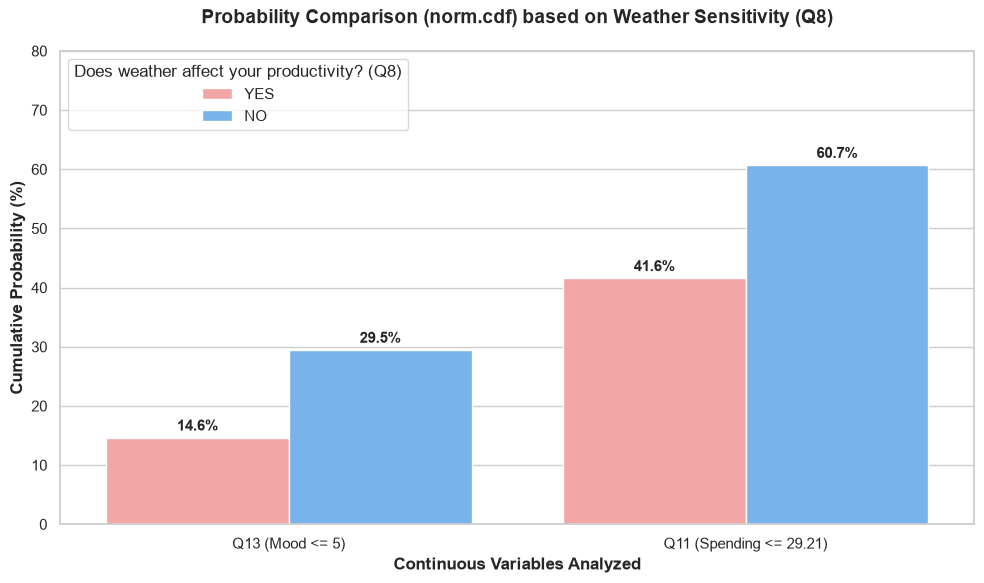

In [65]:

# 1. Manually define the results obtained from the probability test
plot_data = {
    'Variable': ['Q13 (Mood <= 5)', 'Q13 (Mood <= 5)', 'Q11 (Spending <= 29.21)', 'Q11 (Spending <= 29.21)'],
    'Does Weather Affect You? (Q8)': ['YES', 'NO', 'YES', 'NO'],
    'Probability (%)': [14.64, 29.47, 41.58, 60.71]
}

# Convert to DataFrame to plot easily with Seaborn
df_prob_plot = pd.DataFrame(plot_data)

# 2. Set the visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# 3. Draw the comparative bar chart
ax = sns.barplot(
    data=df_prob_plot,
    x='Variable',
    y='Probability (%)',
    hue='Does Weather Affect You? (Q8)',
    palette=['#ff9999', '#66b3ff']
)

# 4. Add numerical percentages on top of each bar for exact reading
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center', 
                    xytext=(0, 8), 
                    textcoords='offset points', 
                    fontweight='bold', fontsize=11)

# 5. Final design customization
plt.title('Probability Comparison (norm.cdf) based on Weather Sensitivity (Q8)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Continuous Variables Analyzed', fontsize=12, fontweight='bold')
plt.ylabel('Cumulative Probability (%)', fontsize=12, fontweight='bold')
plt.ylim(0, 80)
plt.legend(title='Does weather affect your productivity? (Q8)', loc='upper left')

plt.tight_layout()
plt.show()

The visual analysis of the cumulative probabilities (norm.cdf) reveals a fascinating and inverse relationship between weather sensitivity (Q8) and the variables Q13 (Mood) and Q11 (Spending).

Regarding Mood (Q13): People who reported that the weather does NOT affect them (Q8 = NO) have double the probability (29.5%) of experiencing a low mood (score ≤ 5) compared to those who are affected by the weather (14.6%). This counterintuitive finding suggests that individuals who acknowledge their weather sensitivity (Q8 = YES) might be more self-aware and actively manage their emotions, keeping their mood from dropping too low.* Regarding Extra Spending (Q11): The trend is completely different. Individuals who are NOT affected by the weather have a higher probability (60.7%) of spending 29.21 or less, whereas those affected by the weather (Q8 = YES) have only a 41.6% probability of spending that little. This implies that weather-sensitive individuals have a higher likelihood of spending more money (perhaps as a coping mechanism or "retail therapy" on grey days)